# Day 18 — Stationarity of the AirPassengers Series

A time series is **stationary** if its mean, variance, and autocorrelation don't change over time.
We check this with:
1. a time-series plot,
2. rolling mean and rolling standard deviation,
3. the **Augmented Dickey-Fuller (ADF)** test,
4. the **KPSS** test.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss

## 1. Load the data

In [12]:
df = pd.read_csv("../../data/AirPassengers.csv", parse_dates=["Month"], index_col="Month")
df.index.freq = "MS"  # monthly data, stamped at month start
series = df["#Passengers"]

print(df.shape)
df.head()

(144, 1)


,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [13]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   #Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


,#Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


## 2. Plot the series

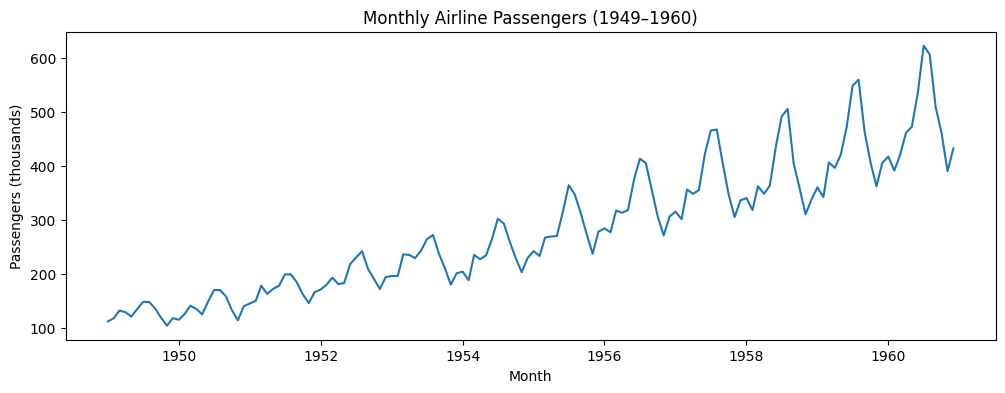

In [14]:
plt.figure(figsize=(12, 4))
plt.plot(series)
plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Month")
plt.ylabel("Passengers (thousands)")
plt.show()

## 3. Rolling statistics

If the series is stationary, the 12-month rolling mean and rolling standard deviation should stay roughly flat.

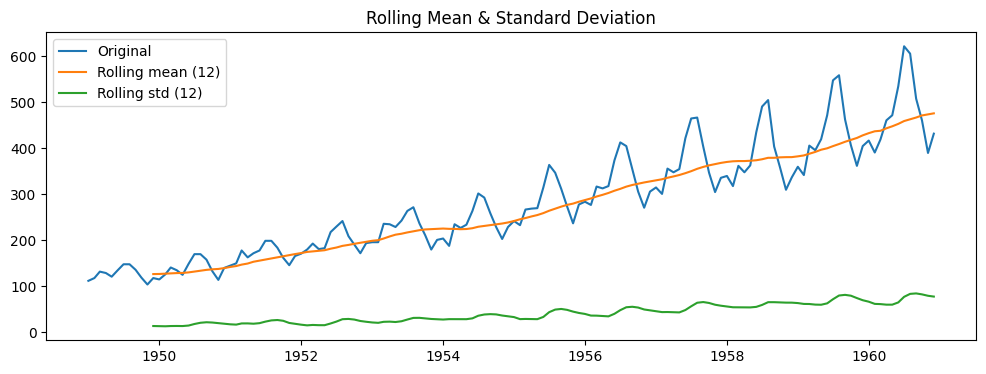

In [15]:
rolling_mean = series.rolling(window=12).mean()
rolling_std = series.rolling(window=12).std()

plt.figure(figsize=(12, 4))
plt.plot(series, label="Original")
plt.plot(rolling_mean, label="Rolling mean (12)")
plt.plot(rolling_std, label="Rolling std (12)")
plt.title("Rolling Mean & Standard Deviation")
plt.legend()
plt.show()

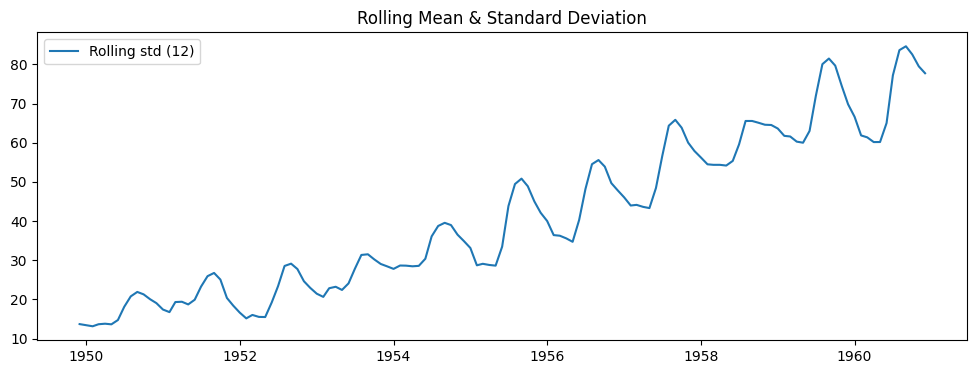

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(rolling_std, label="Rolling std (12)")
plt.title("Rolling Mean & Standard Deviation")
plt.legend()
plt.show()

## 4. Augmented Dickey-Fuller (ADF) test

- **H₀:** the series has a unit root → **non-stationary**
- **H₁:** the series is stationary

If p-value < 0.05, reject H₀ → stationary.

In [17]:
def adf_test(x, name="series"):
    result = adfuller(x.dropna(), autolag="AIC")
    print(f"ADF test — {name}")
    print(f"  Test statistic : {result[0]:.4f}")
    print(f"  p-value        : {result[1]:.4f}")
    print(f"  Lags used      : {result[2]}")
    for key, value in result[4].items():
        print(f"  Critical value ({key}): {value:.4f}")
    print("  =>", "Stationary" if result[1] < 0.05 else "Non-stationary")

adf_test(series, "AirPassengers")

ADF test — AirPassengers
  Test statistic : 0.8154
  p-value        : 0.9919
  Lags used      : 13
  Critical value (1%): -3.4817
  Critical value (5%): -2.8840
  Critical value (10%): -2.5788
  => Non-stationary


/var/folders/w1/8p7_fln1257ft8wkxpm8g7d00000gn/T/ipykernel_52107/1769260761.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(x.dropna(), autolag="AIC")


## 5. KPSS test

KPSS has the **opposite** hypotheses, so it's a good cross-check:

- **H₀:** the series is stationary
- **H₁:** the series is **non-stationary**

If p-value < 0.05, reject H₀ → non-stationary.

In [18]:
import warnings

def kpss_test(x, name="series"):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # KPSS warns when p-value is outside its lookup table
        result = kpss(x.dropna(), regression="c", nlags="auto")
    print(f"KPSS test — {name}")
    print(f"  Test statistic : {result[0]:.4f}")
    print(f"  p-value        : {result[1]:.4f}")
    print(f"  Lags used      : {result[2]}")
    for key, value in result[3].items():
        print(f"  Critical value ({key}): {value:.4f}")
    print("  =>", "Non-stationary" if result[1] < 0.05 else "Stationary")

kpss_test(series, "AirPassengers")

KPSS test — AirPassengers
  Test statistic : 1.6513
  p-value        : 0.0100
  Lags used      : 8
  Critical value (10%): 0.3470
  Critical value (5%): 0.4630
  Critical value (2.5%): 0.5740
  Critical value (1%): 0.7390
  => Non-stationary


## 6. Conclusion

- The plot shows a clear **upward trend** and **yearly seasonality** whose swings grow over time.
- The rolling mean rises steadily and the rolling std also increases.
- **ADF:** p-value is far above 0.05 → we cannot reject the unit root.
- **KPSS:** p-value is below 0.05 → we reject stationarity.

All four checks agree: **the AirPassengers series is non-stationary.**

## 7. Making it stationary

A common fix: take the **log** (stabilises the growing variance), then **difference** (removes the trend).

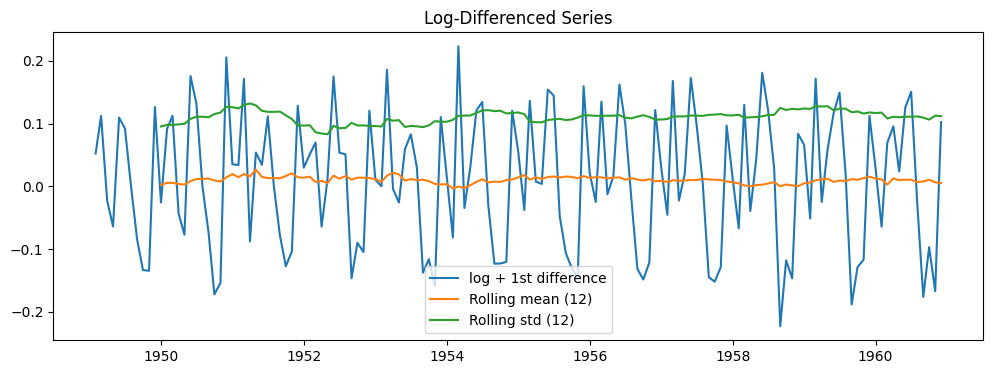

ADF test — log + 1st difference
  Test statistic : -2.7171
  p-value        : 0.0711
  Lags used      : 14
  Critical value (1%): -3.4825
  Critical value (5%): -2.8844
  Critical value (10%): -2.5790
  => Non-stationary

KPSS test — log + 1st difference
  Test statistic : 0.0383
  p-value        : 0.1000
  Lags used      : 6
  Critical value (10%): 0.3470
  Critical value (5%): 0.4630
  Critical value (2.5%): 0.5740
  Critical value (1%): 0.7390
  => Stationary


/var/folders/w1/8p7_fln1257ft8wkxpm8g7d00000gn/T/ipykernel_52107/1769260761.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(x.dropna(), autolag="AIC")


In [22]:
log_diff = np.log(series).diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(log_diff, label="log + 1st difference")
plt.plot(log_diff.rolling(12).mean(), label="Rolling mean (12)")
plt.plot(log_diff.rolling(12).std(), label="Rolling std (12)")
plt.title("Log-Differenced Series")
plt.legend()
plt.show()

adf_test(log_diff, "log + 1st difference")
print()
kpss_test(log_diff, "log + 1st difference")

If the ADF p-value is still above 0.05 after one difference, the remaining yearly seasonality is the cause — a **seasonal difference** (lag 12) handles it:

In [24]:
log_diff_seasonal = np.log(series).diff().diff(12).dropna()

adf_test(log_diff_seasonal, "log + 1st diff + seasonal diff (12)")
print()
kpss_test(log_diff_seasonal, "log + 1st diff + seasonal diff (12)")

ADF test — log + 1st diff + seasonal diff (12)
  Test statistic : -4.4433
  p-value        : 0.0002
  Lags used      : 12
  Critical value (1%): -3.4870
  Critical value (5%): -2.8864
  Critical value (10%): -2.5800
  => Stationary

KPSS test — log + 1st diff + seasonal diff (12)
  Test statistic : 0.0732
  p-value        : 0.1000
  Lags used      : 3
  Critical value (10%): 0.3470
  Critical value (5%): 0.4630
  Critical value (2.5%): 0.5740
  Critical value (1%): 0.7390
  => Stationary


/var/folders/w1/8p7_fln1257ft8wkxpm8g7d00000gn/T/ipykernel_52107/1769260761.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(x.dropna(), autolag="AIC")


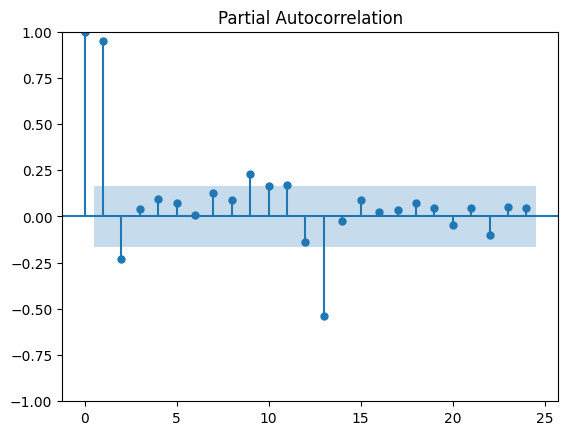

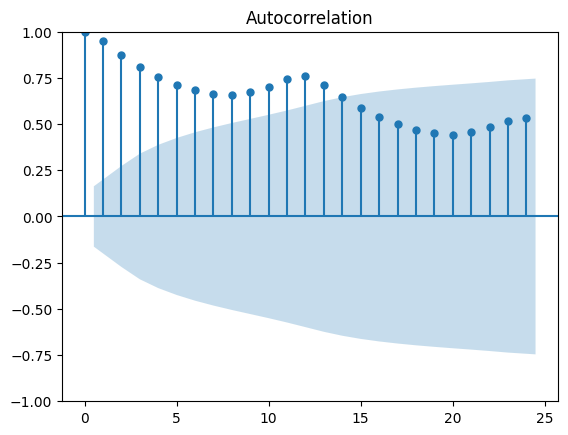

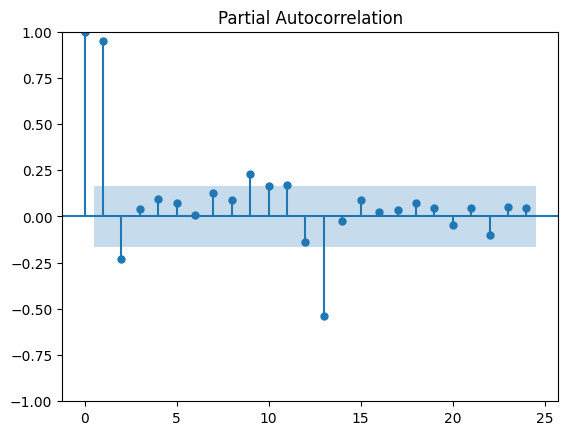

In [27]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(series, lags=24)
plot_pacf(series, lags=24)